In [1]:
#imports
import matplotlib.pyplot as plt
import numpy as np
import pickle

import copy
from pathlib import Path


import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# Set random seeds for reproducibility (same as Exercise 2)
np.random.seed(42)
torch.manual_seed(42)

print("PyTorch Version:", torch.__version__)

PyTorch Version: 2.14.1+cu130


In [2]:
#load the data file
with open("delta_data.pkl", "rb") as file:
    delta_data = pickle.load(file)

In [3]:
def deltas_to_strokes(trajectory):
    """
    Reconstructs (x, y) strokes from (dx, dy, pen_state).
    
    pen_state = 0: pen is DOWN (this step is part of a stroke -> draw it)
    pen_state = 1: pen is UP   (this step is an air move -> skip it)
    pen_state = 2: END         (stop before applying this step)
    """
    strokes = []
    current_stroke = []
    
    x, y = 0.0, 0.0
    
    for dx, dy, pen_state in trajectory:
        if pen_state == 2:
            break

        prev_x, prev_y = x, y
        x = x + dx
        y = y + dy
        
        if pen_state == 0:
            # Pen is DOWN: include this step in the current stroke
            if not current_stroke:
                # First point of the stroke: include the "from" position too
                current_stroke.append((prev_x, prev_y))
            current_stroke.append((x, y))
            
        else:
            # Pen is UP: flying through the air
            # Save the stroke we were drawing (if any) and reset
            if current_stroke:
                strokes.append(current_stroke)
                current_stroke = []
                
    # Save the last stroke if it exists
    if current_stroke:
        strokes.append(current_stroke)        
    return strokes




Character 'a' has 1 strokes after reconstruction.
Character 'b' has 1 strokes after reconstruction.
Character 'c' has 1 strokes after reconstruction.
Character 'A' has 2 strokes after reconstruction.
Character 'B' has 1 strokes after reconstruction.
Character 'C' has 1 strokes after reconstruction.
Character '1' has 1 strokes after reconstruction.
Character '2' has 1 strokes after reconstruction.
Character '3' has 1 strokes after reconstruction.


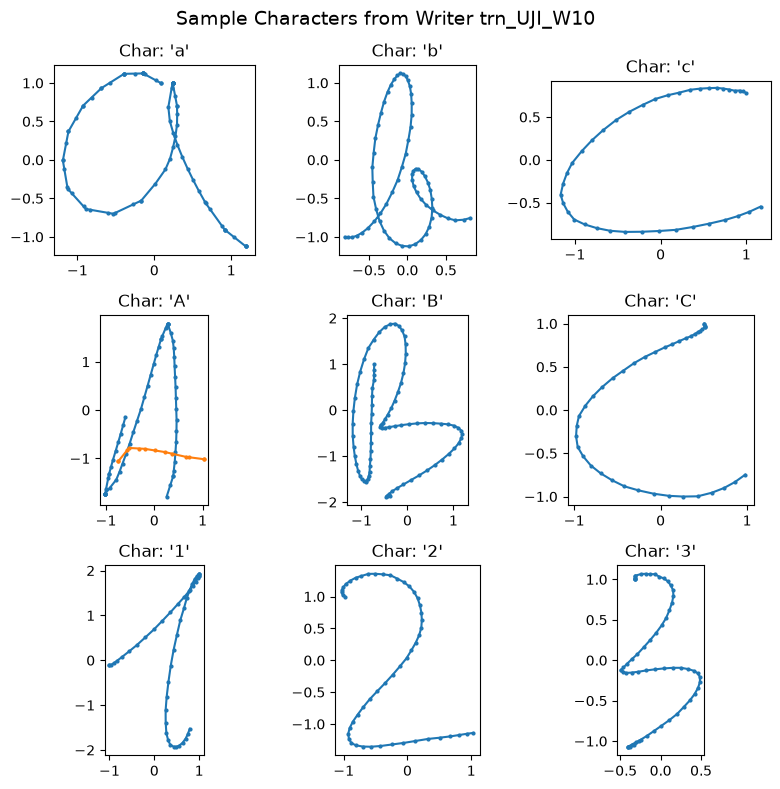

In [4]:
# Plot from delta_data
characters = ['a', 'b', 'c', 'A', 'B', 'C', '1', '2', '3']
writer = "trn_UJI_W10"

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, char in zip(axes.flat, characters):
    # Get the flat trajectory from delta_data
    trajectory = delta_data[writer][char][0]
    
    # Reconstruct strokes from (dx, dy, pen_state)
    strokes = deltas_to_strokes(trajectory)
    print(f"Character '{char}' has {len(strokes)} strokes after reconstruction.")
    
    for stroke in strokes:
        xs = [p[0] for p in stroke]
        ys = [p[1] for p in stroke]
        ax.plot(xs, ys, "-o", markersize=2)
        
    ax.set_aspect("equal")
    ax.set_title(f"Char: '{char}'")

plt.suptitle(f"Sample Characters from Writer {writer}", fontsize=14)
plt.tight_layout()
plt.show()

In [5]:
train_data = {}
val_data = {}
test_data = {}

# 1. Collect all test writer IDs
test_writer_ids = []
for writer_id in delta_data:
    if writer_id.startswith("tst_"):
        test_writer_ids.append(writer_id)

test_writer_ids.sort()

# 2. Split the 20 test writers in half (10 for val, 10 for test)
val_writers = test_writer_ids[:10]
test_writers = test_writer_ids[10:]

# 3. Fill the dictionaries
for writer_id in delta_data:
    if writer_id.startswith("trn_"):
        train_data[writer_id] = delta_data[writer_id]
    elif writer_id in val_writers:
        val_data[writer_id] = delta_data[writer_id]
    elif writer_id in test_writers:
        test_data[writer_id] = delta_data[writer_id]

# 4. Count total samples in each set
def count_samples(dataset):
    total = 0
    for writer_id in dataset:
        for char in dataset[writer_id]:
            total += len(dataset[writer_id][char])
    return total

print(f"Training set:   {len(train_data)} writers | {count_samples(train_data)} samples")
print(f"Validation set: {len(val_data)} writers | {count_samples(val_data)} samples")
print(f"Test set:       {len(test_data)} writers | {count_samples(test_data)} samples")

Training set:   40 writers | 7760 samples
Validation set: 10 writers | 1940 samples
Test set:       10 writers | 1940 samples


Character 'a' has 1 strokes after reconstruction.
Character 'b' has 1 strokes after reconstruction.
Character 'c' has 1 strokes after reconstruction.
Character 'A' has 2 strokes after reconstruction.
Character 'B' has 1 strokes after reconstruction.
Character 'C' has 1 strokes after reconstruction.
Character '1' has 1 strokes after reconstruction.
Character '2' has 1 strokes after reconstruction.
Character '3' has 1 strokes after reconstruction.


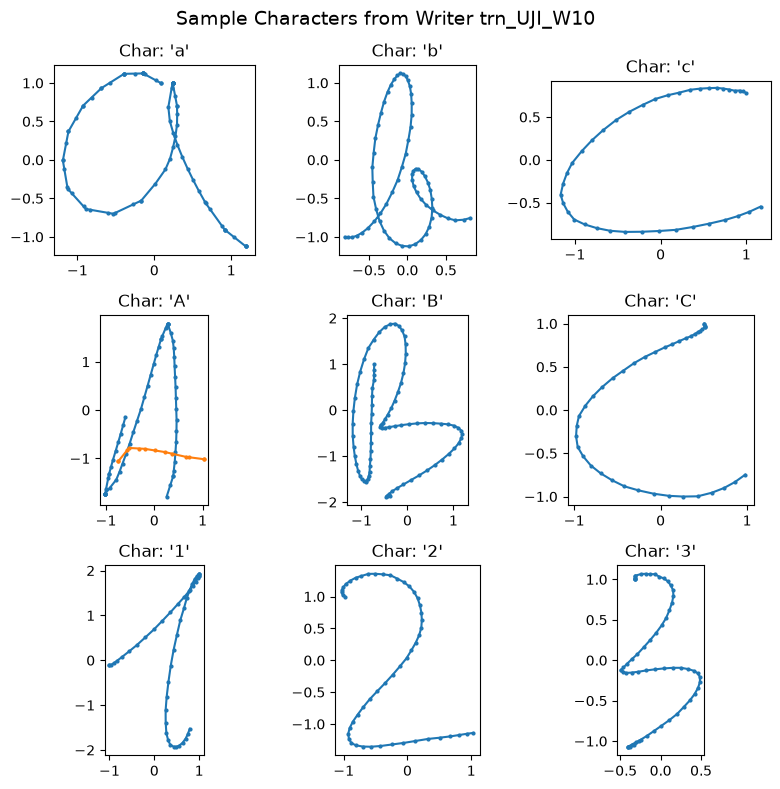

In [6]:
# Plot from delta_data
characters = ['a', 'b', 'c', 'A', 'B', 'C', '1', '2', '3']
writer = "trn_UJI_W10"

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, char in zip(axes.flat, characters):
    # Get the flat trajectory from delta_data
    trajectory = train_data[writer][char][0]
    
    # Reconstruct strokes from (dx, dy, pen_state)
    strokes = deltas_to_strokes(trajectory)
    print(f"Character '{char}' has {len(strokes)} strokes after reconstruction.")
    
    for stroke in strokes:
        xs = [p[0] for p in stroke]
        ys = [p[1] for p in stroke]
        ax.plot(xs, ys, "-o", markersize=2)
        
    ax.set_aspect("equal")
    ax.set_title(f"Char: '{char}'")

plt.suptitle(f"Sample Characters from Writer {writer}", fontsize=14)
plt.tight_layout()
plt.show()

In [7]:
# # Keep originals and add small rotations to training data only.
# ROTATION_ANGLES = (-2.0, 2.0)

# def augment_training_data(data_split, angles):
#     augmented_data = {}

#     for writer_id, characters in data_split.items():
#         augmented_data[writer_id] = {}

#         for char, repetitions in characters.items():
#             augmented_repetitions = []

#             for repetition in repetitions:
#                 trajectory = np.array(
#                     repetition, dtype=np.float32, copy=True
#                 )
#                 augmented_repetitions.append(trajectory)

#                 for angle in angles:
#                     radians = np.deg2rad(angle)
#                     cos_angle = np.cos(radians)
#                     sin_angle = np.sin(radians)

#                     rotation = np.array([
#                         [cos_angle, -sin_angle],
#                         [sin_angle, cos_angle],
#                     ], dtype=np.float32)

#                     rotated = trajectory.copy()

#                     # Rotate movement vectors; preserve pen states.
#                     rotated[:, :2] = trajectory[:, :2] @ rotation.T
#                     augmented_repetitions.append(rotated)

#             augmented_data[writer_id][char] = augmented_repetitions

#     return augmented_data


# # Start from the original samples to avoid accumulating copies on reruns.
# original_train_data = {
#     writer_id: characters
#     for writer_id, characters in delta_data.items()
#     if writer_id.startswith("trn_")
# }

# train_data = augment_training_data(
#     original_train_data, ROTATION_ANGLES
# )

# print(
#     f"Training samples: {count_samples(original_train_data)} originals"
#     f" -> {count_samples(train_data)} after augmentation"
# )
# print(f"Validation samples: {count_samples(val_data)}")
# print(f"Test samples: {count_samples(test_data)}")

In [8]:
# 1. Collect all unique characters and give each one a unique number (0, 1, 2, ...)
all_chars = []
for writer_id in delta_data:
    for char in delta_data[writer_id]:
        if char not in all_chars:
            all_chars.append(char)

#char_to_id = {char: i for i , char in enumerate(all_chars)}
char_to_id = {}
for i in range(len(all_chars)):
    char_to_id[all_chars[i]] = i

num_chars = len(all_chars)

print(f"Total unique characters: {num_chars}")

# 2. Build dataset lists with the shared char_to_id
def build_dataset_lists(data_split):
    c_list = []
    X_list = []
    y_list = []

    for writer_id in data_split:
        for char in data_split[writer_id]:
            c_id = char_to_id[char]  # Uses the shared character ID

            for rep in data_split[writer_id][char]:
                traj = np.array(rep, dtype=np.float32)
                len_traj = len(traj)
                traj = np.array(rep, dtype=np.float32)

                start = np.array([[0.0, 0.0, 1.0]], dtype=np.float32)
                inp = np.concatenate([start, traj[:-1]], axis=0)
                tgt = traj
                c_list.append(c_id)
                X_list.append(inp)
                y_list.append(tgt)

    return c_list, X_list, y_list


c_train, X_train, y_train = build_dataset_lists(train_data)
c_val,   X_val,   y_val   = build_dataset_lists(val_data)
c_test,  X_test,  y_test  = build_dataset_lists(test_data)

Total unique characters: 97


In [9]:
# 1. Find the maximum sequence length across all sets
max_len = 0
for seq in X_train + X_val + X_test:
    if len(seq) > max_len:
        max_len = len(seq)

print("Maximum sequence length:", max_len)


# 2. Simple padding function
def pad_data(c_list, X_list, y_list, max_len):
    total_samples = len(X_list)

    # Create empty arrays filled with zeros
    X_padded = np.zeros((total_samples, max_len, 3), dtype=np.float32)
    y_padded = np.zeros((total_samples, max_len, 3), dtype=np.float32)
    mask = np.zeros((total_samples, max_len), dtype=bool)

    # Fill in the real data
    for i in range(total_samples):
        seq_len = len(X_list[i])

        # Copy original points
        X_padded[i, :seq_len, :] = X_list[i]
        y_padded[i, :seq_len, :] = y_list[i]

        # True for real points, False for padded zeros
        mask[i, :seq_len] = True

    c_array = np.array(c_list, dtype=np.int64)

    return c_array, X_padded, y_padded, mask


# 3. Apply padding to Train, Val, and Test
c_train_pad, X_train_pad, y_train_pad, mask_train = pad_data(c_train, X_train, y_train, max_len)
c_val_pad,   X_val_pad,   y_val_pad,   mask_val   = pad_data(c_val,   X_val,   y_val,   max_len)
c_test_pad,  X_test_pad,  y_test_pad,  mask_test  = pad_data(c_test,  X_test,  y_test,  max_len)

print("Padded X_train shape:", X_train_pad.shape)
print("Mask train shape:    ", mask_train.shape)

Maximum sequence length: 98
Padded X_train shape: (7760, 98, 3)
Mask train shape:     (7760, 98)


In [10]:
# Convert to PyTorch Datasets
train_dataset = TensorDataset(
    torch.tensor(c_train_pad),
    torch.tensor(X_train_pad),
    torch.tensor(y_train_pad),
    torch.tensor(mask_train)
)

val_dataset = TensorDataset(
    torch.tensor(c_val_pad),
    torch.tensor(X_val_pad),
    torch.tensor(y_val_pad),
    torch.tensor(mask_val)
)

test_dataset = TensorDataset(
    torch.tensor(c_test_pad),
    torch.tensor(X_test_pad),
    torch.tensor(y_test_pad),
    torch.tensor(mask_test)
)
train_loader = DataLoader(train_dataset)
val_loader   = DataLoader(val_dataset)
test_loader  = DataLoader(test_dataset)

In [5]:

# # ==============================================================================
# # 1. LSTM MODEL
# # ==============================================================================

# class HandwritingLSTM(nn.Module):

#     def __init__(self, num_chars, hidden_size=32,
#                  num_layers=4, embedding_dim=16):

#         super().__init__()
#         self.char_embedding = nn.Embedding(num_chars, embedding_dim)

#         # LSTM input: dx, dy, pen_state + (character embedding)
#         self.lstm = nn.LSTM(
#             input_size= 3 + embedding_dim,
#             hidden_size=hidden_size,
#             num_layers=num_layers,
#             batch_first=True
#         )

#         # Predict dx and dy
#         self.xy_head = nn.Linear(hidden_size, 2)

#         # Predict binary pen-state logit
#         self.pen_head = nn.Linear(hidden_size, 3)

#     def forward(self, x, c, hidden=None):

#         # x: (batch_size, seq_len, 3)
#         # c: (batch_size,)

#         seq_len = x.shape[1]

#         # Select embedding row using character ID
#         char_emb = self.char_embedding(c.long())

#         # Repeat embedding across all time steps
#         char_emb = char_emb.unsqueeze(1)
#         char_emb = char_emb.expand(-1, seq_len, -1)

#         # Combine trajectory and character information
#         lstm_input = torch.cat(
#             [x, char_emb], dim=-1
#         )

#         # LSTM forward pass
#         output, hidden = self.lstm(lstm_input, hidden)

#         # Coordinate predictions
#         xy_pred = self.xy_head(output)

#         # Pen-state logits
#         pen_logits = self.pen_head(output)

#         return xy_pred, pen_logits, hidden


class HandwritingLSTM(nn.Module):

    def __init__(self, num_chars, hidden_size=128,
                 num_layers=3, embedding_dim=32, dropout_p=0.2):

        super().__init__()
        self.char_embedding = nn.Embedding(num_chars, embedding_dim)
        self.emb_dropout = nn.Dropout(dropout_p * 0.5)  # milder dropout on embeddings

        # 1. Inter-layer dropout inside LSTM
        self.lstm = nn.LSTM(
            input_size=3 + embedding_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout_p if num_layers > 1 else 0.0  # Dropout between LSTM layers
        )

        # 2. Output dropout before prediction heads
        self.out_dropout = nn.Dropout(dropout_p)

        self.xy_head = nn.Linear(hidden_size, 2)
        self.pen_head = nn.Linear(hidden_size, 3)

    def forward(self, x, c, hidden=None):
        seq_len = x.shape[1]

        char_emb = self.char_embedding(c.long())
        char_emb = self.emb_dropout(char_emb)  # Drop out embedding features

        char_emb = char_emb.unsqueeze(1).expand(-1, seq_len, -1)
        lstm_input = torch.cat([x, char_emb], dim=-1)

        output, hidden = self.lstm(lstm_input, hidden)

        # Apply dropout to LSTM outputs before feeding to linear heads
        output = self.out_dropout(output)

        xy_pred = self.xy_head(output)
        pen_logits = self.pen_head(output)

        return xy_pred, pen_logits, hidden

In [12]:

# ==============================================================================
# 2. LOSS FUNCTION AND METRICS
# ==============================================================================

import torch.nn.functional as F

def compute_loss_and_metrics(predictions, targets, mask, coord_std,pen_weight):

    xy_pred, pen_logits, _ = predictions

    # Separate target coordinates and pen states
    xy_target = targets[:, :, :2]
    pen_target = targets[:, :, 2]

    # Pen-state class balancing using inverse weights
    train_pen = train_dataset.tensors[2][:, :, 2].long()
    train_mask = train_dataset.tensors[3].bool()
    class_counts = torch.bincount(train_pen[train_mask], minlength=3).float()
    #pen_class_weights = (class_counts.max() / class_counts)**0.5  # Square-root inverse weights    
    pen_class_weights = ((class_counts.max() / class_counts)).to(device)

    # Ignore padded time steps
    mask = mask.float()
    n_valid = mask.sum().clamp(min=1)

    # ----------------------------------------------------
    # A. Coordinate loss (normalized MSE)
    # ----------------------------------------------------

    # Error relative to the training standard deviation
    xy_error = (xy_pred - xy_target) / coord_std

    # Squared error averaged over x and y
    xy_mse = (xy_error ** 2).mean(dim=-1)

    # Masked coordinate loss
    coord_loss = (xy_mse * mask).sum() / n_valid

    # ----------------------------------------------------
    # B. Pen-state loss (weighted binary cross entropy)
    # ----------------------------------------------------

    pen_logits = pen_logits.squeeze(-1)
  # ----------------------------------------------------
  # Pen-State Cross-Entropy Loss
  # ----------------------------------------------------
    pen_target = pen_target.long().masked_fill(~mask.bool(), 0)
    pen_ce = F.cross_entropy(
        pen_logits.transpose(1, 2),
        pen_target,
        weight=pen_class_weights,
        reduction="none",
    )
    pen_loss = (pen_ce * mask).sum() / n_valid

    loss = coord_loss + pen_weight * pen_loss

    # ----------------------------------------------------
    # C. Total loss
    # ----------------------------------------------------

    loss = coord_loss + pen_weight * pen_loss



    return loss, coord_loss


In [13]:

# ==============================================================================
# 3. TRAINING CONFIGURATION & INITIALIZATION
# ==============================================================================


# Model hyperparameters
LSTM_HIDDEN = 128
LSTM_LAYERS = 3
EMBEDDING_DIM = 64

# Training hyperparameters
BATCH_SIZE = 16
PATIENCE = 6
MIN_IMPROVEMENT = 1e-6
PRINT_EVERY = 1

# Pen-state loss weight
PEN_WEIGHT = 0.1


torch.manual_seed(42)
np.random.seed(42)

# CPU selected because the installed PyTorch CUDA build
# was incompatible with your NVIDIA MX230
device = torch.device("cpu")

print("Using device:", device)

# ----------------------------------------------------
# A. DataLoaders
# ----------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# ----------------------------------------------------
# B. Calculate coordinate standard deviations
# ----------------------------------------------------

train_targets = train_dataset.tensors[2]
train_masks = train_dataset.tensors[3].bool()

valid_xy = train_targets[:, :, :2][train_masks]

coord_std = valid_xy.std(
    dim=0, correction=0
).clamp(min=1e-6).to(device)

print("Coordinate standard deviations:", coord_std)

# ----------------------------------------------------
# C. Initialize the LSTM
# ----------------------------------------------------

model = HandwritingLSTM(
    num_chars=num_chars,
    hidden_size=LSTM_HIDDEN,
    num_layers=LSTM_LAYERS,
    embedding_dim=EMBEDDING_DIM
).to(device)

print(model)

n_parameters = sum(
    p.numel() for p in model.parameters()
)

print(f"\nLearnable parameters: {n_parameters:,}")

# ----------------------------------------------------
# E. Initialize training history
# ----------------------------------------------------

metrics = [
    "loss",
    "coord_loss",
    "pen_loss",
]

history = {}

for metric in metrics:
    history["train_" + metric] = []
    history["val_" + metric] = []

# ----------------------------------------------------
# F. Initialize early stopping and checkpoints
# ----------------------------------------------------

best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
best_epoch = -1

stage_boundary_epoch = None


Using device: cpu
Coordinate standard deviations: tensor([0.1280, 0.1657])
HandwritingLSTM(
  (char_embedding): Embedding(97, 64)
  (emb_dropout): Dropout(p=0.1, inplace=False)
  (lstm): LSTM(67, 128, num_layers=3, batch_first=True, dropout=0.2)
  (out_dropout): Dropout(p=0.2, inplace=False)
  (xy_head): Linear(in_features=128, out_features=2, bias=True)
  (pen_head): Linear(in_features=128, out_features=3, bias=True)
)

Learnable parameters: 371,909


In [14]:

# ==============================================================================
# 4. TRAINING LOOP
# ==============================================================================

def run_epoch(loader, optimizer=None):

    training = optimizer is not None
    model.train(training)

    totals = {
        "loss": 0.0,
        "coord_loss": 0.0,
        "pen_loss": 0.0,
        "pen_acc": 0.0
    }

    total_valid_points = 0
    total_true_up = 0
    total_correct_up = 0

    with torch.set_grad_enabled(training):

        for batch_c, batch_X, batch_y, batch_mask in loader:
            # Move data to device
            batch_c = batch_c.to(device)
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)
            batch_mask = batch_mask.to(device)

            # ----------------------------------------------------
            # A. Forward pass
            # ----------------------------------------------------

            if training:
                optimizer.zero_grad()

            predictions = model(batch_X, batch_c)

            # ----------------------------------------------------
            # B. Calculate loss and metrics
            # ----------------------------------------------------

            loss, coord_l = (
                compute_loss_and_metrics(
                    predictions,
                    batch_y,
                    batch_mask,
                    coord_std,
                    PEN_WEIGHT
                )
            )

            # ----------------------------------------------------
            # C. Backpropagation (training only)
            # ----------------------------------------------------

            if training:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=10
                )

                optimizer.step()

            # ----------------------------------------------------
            # D. Accumulate loss and accuracy
            # ----------------------------------------------------

            n = batch_mask.sum().item()
            total_valid_points += n

            totals["loss"] += loss.item() * n
            totals["coord_loss"] += coord_l.item() * n

            # ----------------------------------------------------
            # E. Calculate pen-up recall counts
            # ----------------------------------------------------

            with torch.no_grad():

                # Predicted class indices: shape [batch_size, seq_len]
                pen_preds = predictions[1].argmax(dim=-1)

                # Class 1 is pen-up
                predicted_up = (pen_preds == 1)

                actual_up = (
                    (batch_y[:, :, 2].long() == 1)
                    & batch_mask.bool()
                )

                total_true_up += actual_up.sum().item()

                total_correct_up += (
                    predicted_up & actual_up
                ).sum().item()

    # ----------------------------------------------------
    # F. Final epoch metrics
    # ----------------------------------------------------

    results = {
        key: value / total_valid_points
        for key, value in totals.items()
    }

    results["coord_rmse"] = np.sqrt(
        results["coord_loss"]
    )

    results["pen_up_recall"] = (
        total_correct_up / total_true_up
        if total_true_up > 0
        else float("nan")
    )

    return results


# ==============================================================================
# MAIN TRAINING PROCESS: TWO STAGES
# ==============================================================================
val_loss=0


# New optimizer, retaining trained model weights
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,             
    weight_decay=1e-4    
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode="min",
    factor=0.5,
    patience=10,        # Increased from 5 to 10
    min_lr=1e-5         # Prevent the LR from dropping below 1e-5mode="min", factor=0.5, patience=5
)


epochs_without_improvement = 0
max_epochs = 1000

try:

    for stage_epoch in range(max_epochs):

        # ----------------------------------------------------
        # A. Training
        # ----------------------------------------------------

        train_results = run_epoch(
            train_loader,
            optimizer=optimizer
        )

        # ----------------------------------------------------
        # B. Validation
        # ----------------------------------------------------

        val_results = run_epoch(
            val_loader,
            optimizer=None
        )
        val_loss = val_results["loss"]
        scheduler.step(val_loss)
        # ----------------------------------------------------
        # C. Record learning curves
        # ----------------------------------------------------

        for metric in metrics:

            history["train_" + metric].append(
                train_results[metric]
            )

            history["val_" + metric].append(
                val_results[metric]
            )

        current_epoch = len(history["train_loss"])

        # ----------------------------------------------------
        # D. Best checkpoint and early stopping
        # ----------------------------------------------------

        val_loss = val_results["loss"]

        if val_loss < best_val_loss - MIN_IMPROVEMENT:

            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = current_epoch - 1

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        # ----------------------------------------------------
        # E. Print training progress
        # ----------------------------------------------------

        if (stage_epoch + 1) % PRINT_EVERY == 0:

            print(
                f"Epoch {current_epoch:3d} | "
                f"Train Loss: {train_results['loss']:.5f} | "
                f"Val Loss: {val_results['loss']:.5f} | "
            )

        # ----------------------------------------------------
        # F. Early stopping
        # ----------------------------------------------------

        if epochs_without_improvement >= PATIENCE:

            print(
                f"\nEarly stopping at epoch {current_epoch}."
            )

            break
except KeyboardInterrupt:
    print("\nTraining interrupted by user.")

# ==============================================================================
# RESTORE BEST MODEL
# ==============================================================================

model.load_state_dict(best_state)

print(
    f"\nBest Epoch: {best_epoch + 1} | "
    f"Best Validation Loss: {best_val_loss:.5f}"
)


/media/ahmed-nabil/university/machine learninig/labs/lab2/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:484: UserWarning: Found GPU0 NVIDIA GeForce MX230 which is of compute capability (CC) 6.1.
The following list shows the CCs this version of PyTorch was built for and the hardware CCs it supports:
- 7.5 which supports hardware CC >=7.5,<8.0
- 8.0 which supports hardware CC >=8.0,<9.0 except {8.7}
- 8.6 which supports hardware CC >=8.6,<9.0 except {8.7}
- 9.0 which supports hardware CC >=9.0,<10.0
- 10.0 which supports hardware CC >=10.0,<11.0 except {10.1}
- 12.0 which supports hardware CC >=12.0,<13.0
Your installed torch==2.14.1+cu130 does not include kernels for this GPU. Reinstall the same version against a CUDA build that does, e.g.:
  For CUDA 12.6 use pip install torch==2.14.1 --index-url https://download.pytorch.org/whl/cu126
  _warn_unsupported_code(d, device_cc, code_ccs)
/media/ahmed-nabil/university/machine learninig/labs/lab2/.venv/lib/python3.12/site-packages

Epoch   1 | Train Loss: 1.05409 | Val Loss: 0.77842 | 
Epoch   2 | Train Loss: 0.67886 | Val Loss: 0.59082 | 
Epoch   3 | Train Loss: 0.56747 | Val Loss: 0.51831 | 
Epoch   4 | Train Loss: 0.51950 | Val Loss: 0.48650 | 
Epoch   5 | Train Loss: 0.49559 | Val Loss: 0.47396 | 
Epoch   6 | Train Loss: 0.46677 | Val Loss: 0.44545 | 
Epoch   7 | Train Loss: 0.45425 | Val Loss: 0.43871 | 
Epoch   8 | Train Loss: 0.43994 | Val Loss: 0.43783 | 
Epoch   9 | Train Loss: 0.43194 | Val Loss: 0.43649 | 
Epoch  10 | Train Loss: 0.42369 | Val Loss: 0.40674 | 
Epoch  11 | Train Loss: 0.41771 | Val Loss: 0.42618 | 
Epoch  12 | Train Loss: 0.41218 | Val Loss: 0.40385 | 
Epoch  13 | Train Loss: 0.40557 | Val Loss: 0.40647 | 
Epoch  14 | Train Loss: 0.40519 | Val Loss: 0.42296 | 
Epoch  15 | Train Loss: 0.39955 | Val Loss: 0.40365 | 
Epoch  16 | Train Loss: 0.39675 | Val Loss: 0.39218 | 
Epoch  17 | Train Loss: 0.39325 | Val Loss: 0.38815 | 
Epoch  18 | Train Loss: 0.38986 | Val Loss: 0.40003 | 
Epoch  19 

In [15]:
model.load_state_dict(best_state)

print(
    f"\nBest Epoch: {best_epoch + 1} | "
    f"Best Validation Loss: {best_val_loss:.5f}"
)



Best Epoch: 37 | Best Validation Loss: 0.36767



STARTING STAGE 2: FINE-TUNING
Epoch  44 | Train Loss: 0.34172 | Val Loss: 0.35096 | LR: 3.0e-05 * (Best)
Epoch  45 | Train Loss: 0.33379 | Val Loss: 0.34822 | LR: 3.0e-05 * (Best)
Epoch  46 | Train Loss: 0.33021 | Val Loss: 0.34721 | LR: 3.0e-05 * (Best)
Epoch  47 | Train Loss: 0.32893 | Val Loss: 0.34699 | LR: 3.0e-05 * (Best)
Epoch  48 | Train Loss: 0.32777 | Val Loss: 0.34595 | LR: 3.0e-05 * (Best)
Epoch  49 | Train Loss: 0.32640 | Val Loss: 0.34582 | LR: 3.0e-05 * (Best)
Epoch  50 | Train Loss: 0.32717 | Val Loss: 0.34563 | LR: 3.0e-05 * (Best)
Epoch  51 | Train Loss: 0.32674 | Val Loss: 0.34508 | LR: 3.0e-05 * (Best)
Epoch  52 | Train Loss: 0.32549 | Val Loss: 0.34493 | LR: 3.0e-05 * (Best)
Epoch  53 | Train Loss: 0.32526 | Val Loss: 0.34451 | LR: 3.0e-05 * (Best)
Epoch  54 | Train Loss: 0.32462 | Val Loss: 0.34471 | LR: 3.0e-05
Epoch  55 | Train Loss: 0.32431 | Val Loss: 0.34387 | LR: 3.0e-05 * (Best)
Epoch  56 | Train Loss: 0.32457 | Val Loss: 0.34402 | LR: 3.0e-05
Epoch  57 | 

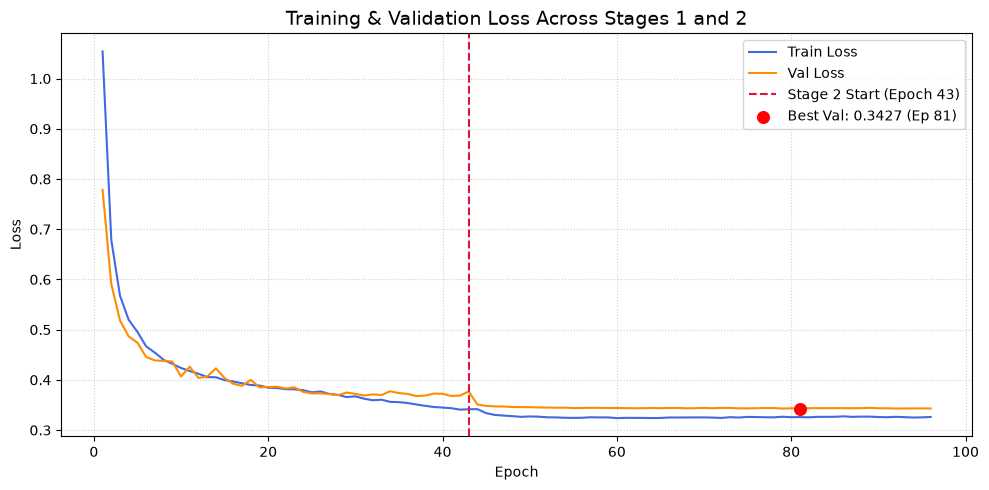


[✓] Successfully saved best model to 'handwriting_lstm_best.pt'


In [16]:
# ==============================================================================
# STAGE 2: FINE-TUNING & CONVERGENCE
# ==============================================================================

print("\n" + "="*50)
print("STARTING STAGE 2: FINE-TUNING")
print("="*50)

# 1. Record the boundary where Stage 2 starts
stage_boundary_epoch = len(history["train_loss"])

# 2. Stage 2 Hyperparameters
STAGE2_MAX_EPOCHS = 1000          # Train for up to 60 more epochs
STAGE2_LR = 3e-5                # Smaller fine-tuning learning rate (was 1e-3)
STAGE2_PATIENCE = 15            # Early stop if no improvement for 15 epochs

# Reset counter for early stopping in this stage
epochs_without_improvement = 0

# 3. New optimizer with lower learning rate for fine adjustments
optimizer_stage2 = torch.optim.Adam(
    model.parameters(),
    lr=STAGE2_LR,
    weight_decay=1e-4
)

# 4. Scheduler with tighter patience for fine-tuning
scheduler_stage2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_stage2,
    mode="min",
    factor=0.5,
    patience=7,
    min_lr=1e-6
)

# ----------------------------------------------------
# STAGE 2 TRAINING LOOP
# ----------------------------------------------------

for stage_epoch in range(STAGE2_MAX_EPOCHS):

    # A. Training
    train_results = run_epoch(
        train_loader,
        optimizer=optimizer_stage2
    )

    # B. Validation
    val_results = run_epoch(
        val_loader,
        optimizer=None
    )

    val_loss = val_results["loss"]
    scheduler_stage2.step(val_loss)

    # C. Record history seamlessly
    for metric in metrics:
        history["train_" + metric].append(train_results[metric])
        history["val_" + metric].append(val_results[metric])

    current_epoch = len(history["train_loss"])

    # D. Checkpoint & Best Model Tracking (against Stage 1 best!)
    if val_loss < best_val_loss - MIN_IMPROVEMENT:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        best_epoch = current_epoch - 1
        epochs_without_improvement = 0
        new_best_marker = " * (Best)"
    else:
        epochs_without_improvement += 1
        new_best_marker = ""

    # E. Print progress
    current_lr = optimizer_stage2.param_groups[0]["lr"]
    print(
        f"Epoch {current_epoch:3d} | "
        f"Train Loss: {train_results['loss']:.5f} | "
        f"Val Loss: {val_results['loss']:.5f} | "
        f"LR: {current_lr:.1e}{new_best_marker}"
    )

    # F. Early Stopping
    if epochs_without_improvement >= STAGE2_PATIENCE:
        print(f"\nEarly stopping triggered at Epoch {current_epoch}.")
        break

# ----------------------------------------------------
# RESTORE OVERALL BEST MODEL
# ----------------------------------------------------
model.load_state_dict(best_state)

print("\n" + "="*50)
print(f"TRAINING COMPLETE across both stages!")
print(f"Overall Best Epoch: {best_epoch + 1}")
print(f"Overall Best Validation Loss: {best_val_loss:.5f}")
print("="*50)

# ==============================================================================
# VISUALIZE: COMPLETE LEARNING CURVES (STAGE 1 + STAGE 2)
# ==============================================================================

total_epochs_trained = len(history["train_loss"])
epochs_range = range(1, total_epochs_trained + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs_range, history["train_loss"], label="Train Loss", color="royalblue")
plt.plot(epochs_range, history["val_loss"], label="Val Loss", color="darkorange")

# Mark boundary between Stage 1 and Stage 2
plt.axvline(
    x=stage_boundary_epoch,
    color="crimson",
    linestyle="--",
    linewidth=1.5,
    label=f"Stage 2 Start (Epoch {stage_boundary_epoch})"
)

# Highlight best epoch
plt.scatter(
    [best_epoch + 1],
    [best_val_loss],
    color="red",
    s=70,
    zorder=5,
    label=f"Best Val: {best_val_loss:.4f} (Ep {best_epoch + 1})"
)

plt.title("Training & Validation Loss Across Stages 1 and 2", fontsize=14)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()



# ==============================================================================
# SAVE TRAINED MODEL & METADATA FOR REUSE
# ==============================================================================

checkpoint_path = "handwriting_lstm_best.pt"

# Bundle the model weights along with the configuration needed to recreate it
checkpoint = {
    # 1. Weights
    "model_state_dict": model.state_dict(),
    
    # 2. Architecture Hyperparameters (needed to re-instantiate HandwritingLSTM)
    "model_config": {
        "num_chars": num_chars,
        "hidden_size": LSTM_HIDDEN,
        "num_layers": LSTM_LAYERS,
        "embedding_dim": EMBEDDING_DIM,
    },
    
    # 3. Data mappings & normalizers (needed for inference / generation)
    "char_to_id": char_to_id,
    "coord_std": coord_std.cpu(),
    
    # 4. Training stats
    "best_epoch": best_epoch + 1,
    "best_val_loss": best_val_loss,
}

torch.save(checkpoint, checkpoint_path)
print(f"\n[✓] Successfully saved best model to '{checkpoint_path}'")



In [ ]:
import copy

# ==============================================================================
# STAGE 3: ADDITIONAL FINE-TUNING
# ==============================================================================

STAGE3_MAX_EPOCHS = 1000
STAGE3_LR = 1e-6
STAGE3_PATIENCE = 15

stage3_boundary_epoch = len(history["train_loss"])
stage3_epochs_without_improvement = 0

# Continue from the best weights from the preceding stages.
model.load_state_dict(best_state)

optimizer_stage3 = torch.optim.Adam(
    model.parameters(),
    lr=STAGE3_LR,
    weight_decay=1e-4,
)

scheduler_stage3 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_stage3,
    mode="min",
    factor=0.5,
    patience=7,
    min_lr=1e-7,
)

print("\n" + "=" * 50)
print("STARTING STAGE 3: ADDITIONAL FINE-TUNING")
print("=" * 50)

# ==============================================================================
# STAGE 3 TRAINING LOOP
# ==============================================================================

try:
    for stage_epoch in range(STAGE3_MAX_EPOCHS):

        # A. Training
        train_results = run_epoch(
            train_loader,
            optimizer=optimizer_stage3,
        )

        # B. Validation
        val_results = run_epoch(
            val_loader,
            optimizer=None,
        )

        val_loss = val_results["loss"]
        scheduler_stage3.step(val_loss)

        # C. Extend the existing learning curves
        for metric in metrics:
            history["train_" + metric].append(train_results[metric])
            history["val_" + metric].append(val_results[metric])

        current_epoch = len(history["train_loss"])

        # D. Track the best checkpoint across all three stages
        if val_loss < best_val_loss - MIN_IMPROVEMENT:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = current_epoch - 1

            stage3_epochs_without_improvement = 0
            new_best_marker = " * (Best)"

        else:
            stage3_epochs_without_improvement += 1
            new_best_marker = ""

        # E. Print progress
        current_lr = optimizer_stage3.param_groups[0]["lr"]

        print(
            f"Epoch {current_epoch:3d} | "
            f"Train Loss: {train_results['loss']:.5f} | "
            f"Val Loss: {val_loss:.5f} | "
            f"LR: {current_lr:.1e}{new_best_marker}"
        )

        # F. Early stopping
        if stage3_epochs_without_improvement >= STAGE3_PATIENCE:
            print(f"\nEarly stopping at epoch {current_epoch}.")
            break

except KeyboardInterrupt:
    print("\nStage 3 interrupted. Restoring the best model.")

finally:
    # Restore the best weights on completion or interruption.
    model.load_state_dict(best_state)
    model.eval()

print("\n" + "=" * 50)
print("TRAINING COMPLETE")
print(f"Overall Best Epoch: {best_epoch + 1}")
print(f"Overall Best Validation Loss: {best_val_loss:.5f}")
print("=" * 50)

# ==============================================================================
# SAVE BEST MODEL AFTER STAGE 3
# ==============================================================================

stage3_checkpoint_path = "handwriting_lstm_stage3_best.pt"

stage3_checkpoint = {
    "model_state_dict": model.state_dict(),

    "model_config": {
        "num_chars": num_chars,
        "hidden_size": LSTM_HIDDEN,
        "num_layers": LSTM_LAYERS,
        "embedding_dim": EMBEDDING_DIM,
    },

    "char_to_id": char_to_id,
    "coord_std": coord_std.cpu(),

    "best_epoch": best_epoch + 1,
    "best_val_loss": best_val_loss,

    "history": history,
    "stage3_boundary_epoch": stage3_boundary_epoch,
}

torch.save(stage3_checkpoint, stage3_checkpoint_path)

print(f"\nSaved best model to '{stage3_checkpoint_path}'")

# ==============================================================================
# VISUALIZE LEARNING CURVES: STAGES 1, 2, AND 3
# ==============================================================================

epochs_range = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Train Loss",
    color="royalblue",
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss",
    color="darkorange",
)

plt.axvline(
    x=stage_boundary_epoch,
    color="crimson",
    linestyle="--",
    label="Stage 2 start",
)

plt.axvline(
    x=stage3_boundary_epoch,
    color="purple",
    linestyle="--",
    label="Stage 3 start",
)

if best_epoch >= 0:
    plt.scatter(
        best_epoch + 1,
        best_val_loss,
        color="red",
        s=70,
        zorder=5,
        label=f"Best: {best_val_loss:.4f} (Epoch {best_epoch + 1})",
    )

plt.title("Training and Validation Loss Across Stages 1, 2, and 3")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


STARTING STAGE 3: ADDITIONAL FINE-TUNING
Epoch 100 | Train Loss: 0.32551 | Val Loss: 0.34225 | LR: 1.0e-06
Epoch 101 | Train Loss: 0.32475 | Val Loss: 0.34227 | LR: 1.0e-06
Epoch 102 | Train Loss: 0.32463 | Val Loss: 0.34232 | LR: 1.0e-06
Epoch 103 | Train Loss: 0.32497 | Val Loss: 0.34238 | LR: 1.0e-06
Epoch 104 | Train Loss: 0.32463 | Val Loss: 0.34238 | LR: 1.0e-06
Epoch 105 | Train Loss: 0.32408 | Val Loss: 0.34239 | LR: 1.0e-06
Epoch 106 | Train Loss: 0.32486 | Val Loss: 0.34244 | LR: 1.0e-06
Epoch 107 | Train Loss: 0.32379 | Val Loss: 0.34246 | LR: 1.0e-06
Epoch 108 | Train Loss: 0.32441 | Val Loss: 0.34246 | LR: 5.0e-07


### Load the latest saved model (skip training)
Run the imports cell and the cell defining `HandwritingLSTM`, then run the cell below. It selects the most recently modified `handwriting_lstm*.pt` checkpoint and restores the model for inference. You can skip all training cells.

To plot generated characters, also run the `deltas_to_strokes` definition, then the `generate_trajectory` definition and the sample-character plotting cell below.


In [9]:
# Load the most recently saved checkpoint without retraining.
checkpoint_paths = list(Path(".").glob("handwriting_lstm_stage3_best.pt"))
if not checkpoint_paths:
    raise FileNotFoundError("No handwriting_lstm*.pt checkpoints found in the current directory.")

checkpoint_path = max(checkpoint_paths, key=lambda path: path.stat().st_mtime_ns)

# Use CPU, matching this notebook's training configuration.
device = torch.device("cpu")
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)

model = HandwritingLSTM(**checkpoint["model_config"]).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

char_to_id = checkpoint["char_to_id"]
num_chars = checkpoint["model_config"]["num_chars"]
coord_std = checkpoint["coord_std"].to(device)

print(f"Loaded: {checkpoint_path.name}")
print(f"Saved best epoch: {checkpoint['best_epoch']}")
print(f"Available characters: {len(char_to_id)}")


Loaded: handwriting_lstm_stage3_best.pt
Saved best epoch: 98
Available characters: 97


In [10]:
@torch.inference_mode()
def generate_trajectory(model, char, char_to_id, max_steps=97):
    """Return an (N, 3) NumPy array of (dx, dy, pen_state).

    Pen states: 0 = draw, 1 = pen up, 2 = end of character.
    """
    if char not in char_to_id:
        raise ValueError(f"Unknown character: {char!r}")
    if max_steps < 1:
        raise ValueError("max_steps must be positive.")

    parameter = next(model.parameters())
    c = torch.tensor(
        [char_to_id[char]], dtype=torch.long, device=parameter.device
    )

    # Same start token used during training.
    x = parameter.new_tensor([[[0.0, 0.0, 1.0]]])
    hidden = None
    trajectory = []

    was_training = model.training
    model.eval()

    try:
        for _ in range(max_steps):
            xy_pred, pen_logits, hidden = model(x, c, hidden)

            pen_state = pen_logits[0, -1].argmax()
            step = torch.cat([
                xy_pred[0, -1],
                pen_state.to(dtype=parameter.dtype).reshape(1),
            ])
            trajectory.append(step)

            if pen_state.item() == 2:
                break

            # Feed the predicted point into the next step.
            x = step.reshape(1, 1, 3)

    finally:
        model.train(was_training)

    return torch.stack(trajectory).cpu().numpy()

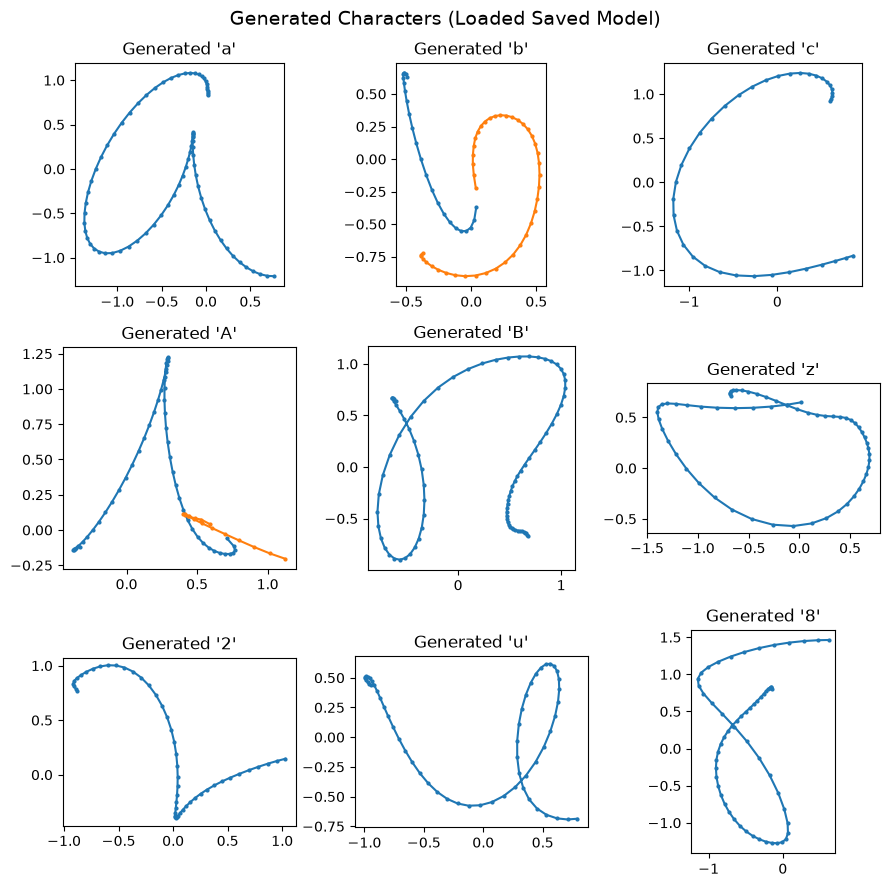

In [19]:
# ==============================================================================
# VISUALIZE: GENERATE SAMPLE CHARACTERS WITH BEST MODEL
# ==============================================================================

sample_chars = ['a', 'b', 'c', 'A', 'B', 'z', '2', 'u', '8']
fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for ax, char in zip(axes.flat, sample_chars):
    if char in char_to_id:
        gen_trajectory = generate_trajectory(model, char, char_to_id, max_steps=97)
        strokes = deltas_to_strokes(gen_trajectory)
        for stroke in strokes:
            xs = [p[0] for p in stroke]
            ys = [p[1] for p in stroke]
            ax.plot(xs, ys, "-o", markersize=2)
        ax.set_aspect("equal")
        ax.set_title(f"Generated '{char}'")
    else:
        ax.axis("off")

plt.suptitle("Generated Characters (Loaded Saved Model)", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# VISUALIZE: GENERATE EVERY CHARACTER IN DELTA_DATA WITH BEST MODEL
# ==============================================================================

# Collect unique characters across all writers.
generated_chars = sorted({
    char
    for writer_chars in delta_data.values()
    for char in writer_chars
})
if not generated_chars:
    raise ValueError("delta_data contains no characters to plot.")

ncols = min(8, len(generated_chars))
nrows = (len(generated_chars) + ncols - 1) // ncols
fig, axes = plt.subplots(
    nrows, ncols, figsize=(3 * ncols, 3 * nrows), squeeze=False
)

for ax, char in zip(axes.flat, generated_chars):
    if char in char_to_id:
        gen_trajectory = generate_trajectory(model, char, char_to_id, max_steps=97)
        strokes = deltas_to_strokes(gen_trajectory)
        for stroke in strokes:
            xs = [p[0] for p in stroke]
            ys = [p[1] for p in stroke]
            ax.plot(xs, ys, "-o", markersize=2)
        ax.set_aspect("equal")
        ax.set_title(f"Generated {char!r}")
    else:
        ax.set_title(f"{char!r}: unavailable in saved model")
        ax.axis("off")

# Hide unused grid positions.
for ax in axes.flat[len(generated_chars):]:
    ax.axis("off")

fig.suptitle("All Generated Characters (Loaded Saved Model)", fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()
